### **NAMA : NIRWANA**  
### **NIM : H061241011 (C)**  
### **MATKUL : KECERDASAN ARTIFISIAL**
### **MEMBUAT PROMPT AI UNTUK STUDI KASUS GEOFISIKA** 



## Latar Belakang

Kecerdasan buatan (AI) dapat membantu pekerjaan geofisika, tetapi kualitas jawabannya sangat
bergantung pada kejelasan perintah yang kita tulis. Perintah yang samar membuat AI cenderung
menebak satuan, asumsi, atau data yang sebenarnya tidak ada. Karena itu, pada tugas ini perintah
ditulis sebagai *prompt* terstruktur: pekerjaan, data, batasan, dan hasil yang diharapkan
dinyatakan lebih dahulu sebelum AI diminta bekerja.

## Tujuan Tugas

- Menyusun lima prompt untuk lima permasalahan geofisika yang berbeda.
- Menerapkan unsur-unsur prompt yang baik menurut buku *AI Cookbook untuk Earth Sciences*.
- Menuliskan rencana output dalam bentuk narasi, tanpa menyelesaikan masalahnya terlebih dahulu.

## Unsur Prompt yang Digunakan

Setiap prompt memuat delapan unsur, ditulis berurutan dari R sampai V:

1. **Role (R)**: peran yang diminta dari AI, misalnya reviewer data atau analis pemula, agar cara kerjanya searah dengan kebutuhan.
2. **Task (T)**: pekerjaan yang harus dilakukan, ditulis dengan kata kerja yang jelas dan bisa diperiksa hasilnya.
3. **Context (C)**: alasan pekerjaan dilakukan dan untuk apa hasilnya dipakai.
4. **Input (I)**: data yang diberikan, lengkap dengan nama file, kolom, dan satuannya.
5. **Constraints (K)**: hal yang tidak boleh dilakukan AI, misalnya mengubah data asli atau menebak nilai yang tidak diketahui.
6. **Output (O)**: gambaran hasil yang diharapkan berupa file dan isinya. Ini rencana, bukan hasil.
7. **Quality criteria (Q)**: ukuran untuk menilai apakah hasil sudah baik.
8. **Optional verification (V)**: pemeriksaan singkat untuk memastikan hasil benar, beserta tindakan jika gagal.

## Cara Membaca Dokumen Ini

- Setiap prompt diberi judul dan nomor, lalu tiap unsurnya ditandai dengan `[R]`, `[T]`, `[C]`, `[I]`, `[K]`, `[O]`, `[Q]`, dan `[V]`.
- Kalimat di bawah setiap tanda adalah isi prompt untuk unsur tersebut.
- Tulisan `{{...}}` menandai nilai yang belum diketahui dan harus diisi atau ditanyakan lebih dulu.
- Bagian Output hanya berupa narasi rencana hasil, tidak berbentuk gambar.



## Ringkasan Lima Studi Kasus

1. **Gravitasi**: koreksi free-air dan Bouguer pada data gravitasi sederhana.
2. **Magnetik**: koreksi variasi harian dan anomali medan magnet total.
3. **Geolistrik**: resistivitas semu dari data sounding konfigurasi Schlumberger.
4. **Seismologi**: jarak episenter dari selisih waktu tiba gelombang S dan P.
5. **Klimatologi**: rata-rata dan anomali suhu udara bulanan.

---


## Prompt 1 — Gravitasi: Koreksi Free-Air dan Bouguer pada Data Gravitasi Sederhana

### [R] Role
Bertindaklah sebagai asisten geofisika eksplorasi yang teliti pada satuan dan rumus koreksi. Fokus pada urutan koreksi dan kebenaran satuan.

### [T] Task
Rencanakan langkah menghitung anomali Bouguer dari data gravitasi observasi di beberapa titik, mencakup koreksi lintang, free-air, dan Bouguer. Jangan menafsirkan struktur bawah permukaan.

### [C] Context
Latihan mata kuliah untuk memahami alur koreksi gravitasi. Hasil hanya dipakai untuk belajar, bukan untuk survei sebenarnya.

### [I] Input
- `data/gravitasi.csv`: kolom `titik`, `lat` (derajat), `elevasi_m` (meter), `g_obs_mgal` (mGal).
- Densitas Bouguer: `{{2,67}}` g/cm3.

### [K] Constraints
- Jangan mengubah data asli.
- Jangan menebak densitas atau satuan yang tidak tertulis; tanyakan bila tidak jelas.
- Tulis rumus yang dipakai pada setiap koreksi.
- Software: Python dengan pandas dan numpy; tanpa jaringan.

### [O] Output (rencana teks)
- `results/gravitasi/tabel_koreksi.csv`: `titik`, `koreksi_lintang`, `free_air`, `bouguer`, `anomali_bouguer_mgal`.
- `results/gravitasi/rencana.md`: narasi urutan langkah koreksi dan alasan tiap langkah.

### [Q] Quality criteria
- Satuan mGal dan meter ditulis eksplisit.
- Jumlah titik pada output sama dengan input.
- Setiap koreksi disertai rumusnya.

### [V] Optional verification
- Check: hitung satu titik secara manual. Expected: sama dengan baris pada tabel. Jika gagal: periksa rumus dan satuan.

---


=== TABEL KOREKSI GRAVITASI (satuan: mGal; elevasi: meter) ===
titik  koreksi_lintang  free_air  bouguer  anomali_bouguer_mgal
   G1       978072.646     3.703    1.343                   1.2
   G2       978072.726     7.869    2.855                   1.0
   G3       978072.806    14.813    5.374                   0.6
   G4       978072.886    23.299    8.452                  -0.2
   G5       978072.966    33.946   12.315                  -1.5
   G6       978073.046    29.317   10.636                  -0.8
   G7       978073.126    18.670    6.773                   0.1
   G8       978073.206     9.258    3.359                   0.9

Rumus yang dipakai:
  koreksi lintang : g_n = 978031.846*(1 + 0.005278895 sin^2(lat) + 0.000023462 sin^4(lat))  [mGal]
  free-air        : FA  = 0.3086 * h  [mGal]
  Bouguer         : BC  = 0.04193 * rho * h  [mGal], rho = 2.67 g/cm3
  anomali Bouguer : AB  = g_obs - g_n + FA - BC  [mGal]

=== KRITERIA KUALITAS ===
Jumlah titik input = 8, output = 8 -> SAMA


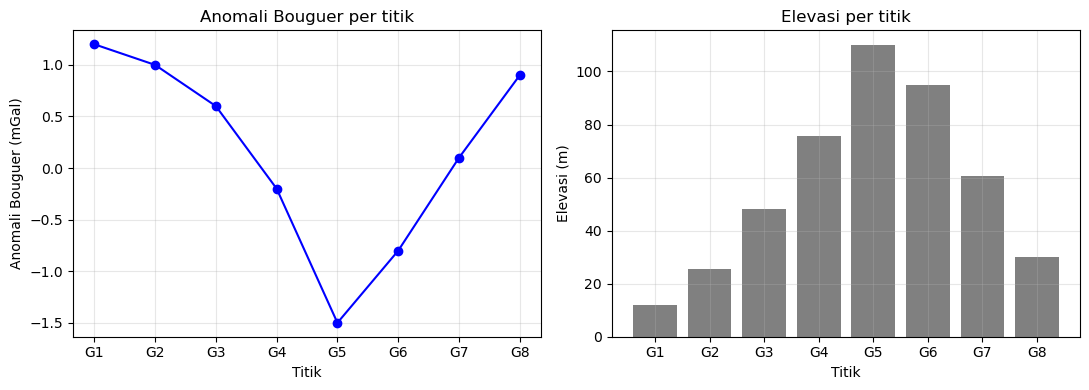

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("data", exist_ok=True)
os.makedirs("results/gravitasi", exist_ok=True)

# DATA CONTOH (dibuat sendiri untuk latihan), disimpan sebagai data/gravitasi.csv
contoh = pd.DataFrame({
    "titik": ["G1", "G2", "G3", "G4", "G5", "G6", "G7", "G8"],
    "lat": [-5.1, -5.105, -5.11, -5.115, -5.12, -5.125, -5.13, -5.135],
    "elevasi_m": [12.0, 25.5, 48.0, 75.5, 110.0, 95.0, 60.5, 30.0],
    "g_obs_mgal": [978071.486, 978068.711, 978063.967, 978057.839, 978049.835, 978053.564, 978061.329, 978068.207]})
contoh.to_csv("data/gravitasi.csv", index=False)

# [I] BACA DATA ASLI (tidak diubah, hanya dibaca)
data = pd.read_csv("data/gravitasi.csv")
rho_bouguer = 2.67        # g/cm3 (nilai dari prompt)

# [K] PEMERIKSAAN KOLOM DAN DATA KOSONG
kolom_wajib = ["titik", "lat", "elevasi_m", "g_obs_mgal"]
kurang = [k for k in kolom_wajib if k not in data.columns]
if len(kurang) > 0:
    raise SystemExit("Data tidak memadai, kolom belum ada: %s" % kurang)
if data[kolom_wajib].isna().any().any():
    raise SystemExit("Ada nilai kosong pada data. Lengkapi dulu, jangan ditebak.")

# [T] HITUNG KOREKSI
# 1) Koreksi lintang (gravitasi normal, rumus GRS80 yang disederhanakan), satuan mGal
#    g_n = 978031.846 * (1 + 0.005278895 sin^2(lat) + 0.000023462 sin^4(lat))
lat_rad = np.radians(data["lat"])
koreksi_lintang = 978031.846 * (1 + 0.005278895 * np.sin(lat_rad)**2 + 0.000023462 * np.sin(lat_rad)**4)

# 2) Koreksi free-air: FA = 0.3086 * h  (mGal, h dalam meter)
free_air = 0.3086 * data["elevasi_m"]

# 3) Koreksi Bouguer: BC = 0.04193 * rho * h  (mGal, rho dalam g/cm3, h dalam meter)
bouguer = 0.04193 * rho_bouguer * data["elevasi_m"]

# 4) Anomali Bouguer sederhana (tanpa koreksi medan): AB = g_obs - g_n + FA - BC
anomali_bouguer = data["g_obs_mgal"] - koreksi_lintang + free_air - bouguer

tabel = pd.DataFrame({
    "titik": data["titik"],
    "koreksi_lintang": koreksi_lintang.round(3),
    "free_air": free_air.round(3),
    "bouguer": bouguer.round(3),
    "anomali_bouguer_mgal": anomali_bouguer.round(3)})
tabel.to_csv("results/gravitasi/tabel_koreksi.csv", index=False)

print("=== TABEL KOREKSI GRAVITASI (satuan: mGal; elevasi: meter) ===")
print(tabel.to_string(index=False))
print("\nRumus yang dipakai:")
print("  koreksi lintang : g_n = 978031.846*(1 + 0.005278895 sin^2(lat) + 0.000023462 sin^4(lat))  [mGal]")
print("  free-air        : FA  = 0.3086 * h  [mGal]")
print("  Bouguer         : BC  = 0.04193 * rho * h  [mGal], rho = %.2f g/cm3" % rho_bouguer)
print("  anomali Bouguer : AB  = g_obs - g_n + FA - BC  [mGal]")

# [Q] KRITERIA KUALITAS
print("\n=== KRITERIA KUALITAS ===")
print("Jumlah titik input = %d, output = %d -> %s" % (len(data), len(tabel), "SAMA" if len(data) == len(tabel) else "TIDAK SAMA"))

# [V] VERIFIKASI: hitung titik pertama secara manual
lat1 = data["lat"].iloc[0]
h1 = data["elevasi_m"].iloc[0]
g1 = data["g_obs_mgal"].iloc[0]
s1 = np.sin(np.radians(lat1))
gn1 = 978031.846 * (1 + 0.005278895 * s1**2 + 0.000023462 * s1**4)
ab_manual = g1 - gn1 + 0.3086 * h1 - 0.04193 * rho_bouguer * h1
print("\n=== VERIFIKASI TITIK %s ===" % data["titik"].iloc[0])
print("Manual : %.3f mGal | Tabel : %.3f mGal" % (ab_manual, tabel["anomali_bouguer_mgal"].iloc[0]))
if abs(ab_manual - tabel["anomali_bouguer_mgal"].iloc[0]) < 0.001:
    print("Hasil: LULUS")
else:
    print("Hasil: GAGAL -> periksa rumus dan satuan")

# [O] RENCANA.MD (narasi)
rencana = """# Rencana Pengolahan Data Gravitasi

1. Baca data/gravitasi.csv tanpa mengubah isinya (kolom titik, lat, elevasi_m, g_obs_mgal).
2. Hitung gravitasi normal tiap titik dari lintang (koreksi lintang), satuan mGal.
3. Hitung koreksi free-air dari elevasi: FA = 0.3086 * h. Alasan: gravitasi berkurang bila titik lebih tinggi dari datum.
4. Hitung koreksi Bouguer: BC = 0.04193 * rho * h dengan rho = %.2f g/cm3. Alasan: massa batuan di antara titik dan datum menambah gravitasi.
5. Hitung anomali Bouguer: AB = g_obs - g_n + FA - BC.
6. Periksa jumlah titik dan hitung satu titik secara manual sebagai verifikasi.
""" % rho_bouguer
with open("results/gravitasi/rencana.md", "w", encoding="utf-8") as f:
    f.write(rencana)

# GRAFIK
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(data["titik"], anomali_bouguer, "bo-")
ax[0].set_xlabel("Titik"); ax[0].set_ylabel("Anomali Bouguer (mGal)")
ax[0].set_title("Anomali Bouguer per titik"); ax[0].grid(True, alpha=.3)
ax[1].bar(data["titik"], data["elevasi_m"], color="gray")
ax[1].set_xlabel("Titik"); ax[1].set_ylabel("Elevasi (m)")
ax[1].set_title("Elevasi per titik"); ax[1].grid(True, alpha=.3)
plt.tight_layout()
plt.savefig("results/gravitasi/grafik_gravitasi.png", dpi=150)
plt.show()


## Prompt 2 — Magnetik: Koreksi Variasi Harian dan Anomali Medan Magnet Total

### [R] Role
Bertindaklah sebagai reviewer data magnetik pemula. Fokus pada variasi harian, kecocokan waktu pengukuran, dan nilai medan utama.

### [T] Task
Rencanakan langkah menghitung anomali medan magnet total: koreksi variasi harian memakai data base station, lalu kurangi medan utama (IGRF). Jangan menginterpretasi sumber anomali.

### [C] Context
Latihan mata kuliah untuk memahami alur pengolahan data magnetik. Hasil hanya untuk belajar dan bukan untuk keputusan lapangan.

### [I] Input
- `data/magnetik_lapangan.csv`: kolom `titik`, `waktu`, `H_nT` (nT).
- `data/magnetik_base.csv`: kolom `waktu`, `H_nT` (nT). Nilai IGRF: `{{nT}}`.

### [K] Constraints
- Jangan mengubah data asli.
- Jangan menebak zona waktu atau nilai IGRF; tanyakan bila tidak jelas.
- Software: Python dengan pandas; tanpa jaringan.

### [O] Output (rencana teks)
- `results/magnetik/anomali.csv`: `titik`, `H_terkoreksi_nT`, `anomali_nT`.
- `results/magnetik/rencana.md`: narasi langkah koreksi dan cara mencocokkan waktu titik dengan base station.

### [Q] Quality criteria
- Satuan nT ditulis eksplisit.
- Waktu titik dan base station dicocokkan dan caranya dijelaskan.
- Jumlah titik pada output sama dengan input.

### [V] Optional verification
- Check: hitung satu titik secara manual. Expected: sama dengan baris pada tabel. Jika gagal: periksa pencocokan waktu.

---


=== ANOMALI MEDAN MAGNET TOTAL (satuan: nT) ===
titik               waktu     H_nT  variasi_harian_nT  H_terkoreksi_nT  anomali_nT
   M1 2025-03-10 08:05:00 44906.22               0.89         44905.33        5.33
   M2 2025-03-10 08:25:00 44918.04               4.81         44913.23       13.23
   M3 2025-03-10 08:45:00 44934.64               9.24         44925.40       25.40
   M4 2025-03-10 09:05:00 44960.77              12.23         44948.54       48.54
   M5 2025-03-10 09:25:00 44984.33              13.84         44970.49       70.49
   M6 2025-03-10 09:45:00 44954.68              13.97         44940.71       40.71
   M7 2025-03-10 10:05:00 44928.43              13.21         44915.22       15.22
   M8 2025-03-10 10:25:00 44901.18              10.32         44890.86       -9.14
   M9 2025-03-10 10:45:00 44882.94               7.88         44875.06      -24.94
  M10 2025-03-10 11:05:00 44896.53               3.88         44892.65       -7.35

Rumus yang dipakai:
  variasi harian  

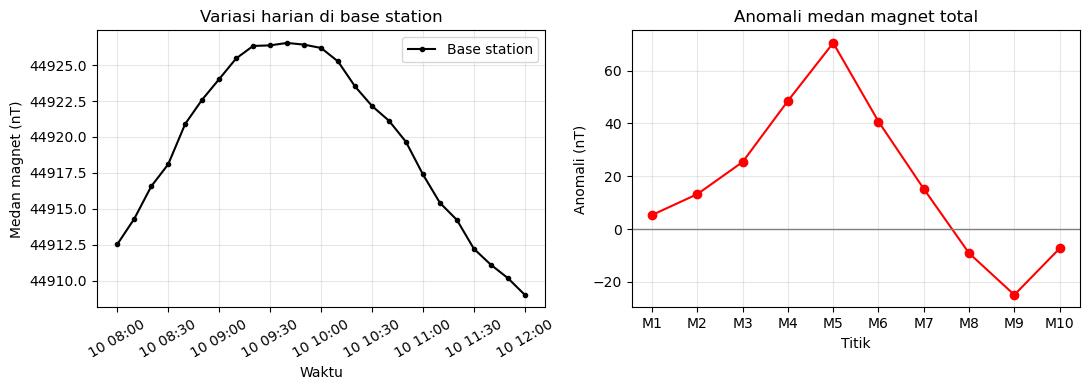

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("data", exist_ok=True)
os.makedirs("results/magnetik", exist_ok=True)

# DATA CONTOH (dibuat sendiri untuk latihan)
np.random.seed(11)
igrf = 44900.0            # nT (nilai contoh; ganti dengan nilai IGRF lokasi survei)

# Data base station: tiap 10 menit, pukul 08:00 sampai 12:00
waktu_base = pd.date_range("2025-03-10 08:00:00", "2025-03-10 12:00:00", freq="10min")
menit = np.arange(len(waktu_base)) * 10
drift = 12 * np.sin(2 * np.pi * menit / 360) + 0.03 * menit
H_base = 44912.0 + drift + np.random.normal(0, 0.3, len(waktu_base))
pd.DataFrame({"waktu": waktu_base, "H_nT": H_base.round(2)}).to_csv("data/magnetik_base.csv", index=False)

# Data lapangan: 10 titik, selang 20 menit mulai 08:05
waktu_lap = pd.date_range("2025-03-10 08:05:00", periods=10, freq="20min")
anomali_asli = np.array([5, 12, 25, 48, 70, 40, 15, -10, -25, -8])
menit_lap = np.arange(len(waktu_lap)) * 20 + 5
drift_lap = 12 * np.sin(2 * np.pi * menit_lap / 360) + 0.03 * menit_lap
H_lap = igrf + anomali_asli + drift_lap + np.random.normal(0, 0.3, len(waktu_lap))
pd.DataFrame({"titik": ["M%d" % (i + 1) for i in range(10)],
              "waktu": waktu_lap, "H_nT": H_lap.round(2)}).to_csv("data/magnetik_lapangan.csv", index=False)

# [I] BACA DATA ASLI
lap = pd.read_csv("data/magnetik_lapangan.csv", parse_dates=["waktu"])
base = pd.read_csv("data/magnetik_base.csv", parse_dates=["waktu"]).sort_values("waktu").reset_index(drop=True)

# [K] PEMERIKSAAN DATA
if lap["H_nT"].isna().any() or base["H_nT"].isna().any():
    raise SystemExit("Ada nilai kosong pada data magnetik.")
if lap["waktu"].min() < base["waktu"].min() or lap["waktu"].max() > base["waktu"].max():
    raise SystemExit("Waktu titik lapangan di luar rentang base station. Zona waktu atau data perlu dicek.")

# [T] KOREKSI VARIASI HARIAN
# Waktu diubah ke detik sejak bacaan pertama base station, lalu nilai base
# pada waktu tiap titik dicari dengan interpolasi linear.
t0 = base["waktu"].iloc[0]
t_base = (base["waktu"] - t0).dt.total_seconds().values
t_lap = (lap["waktu"] - t0).dt.total_seconds().values
base_pada_titik = np.interp(t_lap, t_base, base["H_nT"].values)

base_ref = base["H_nT"].iloc[0]                  # nilai acuan base station (awal survei)
variasi_harian = base_pada_titik - base_ref      # nT
H_terkoreksi = lap["H_nT"] - variasi_harian      # nT
anomali = H_terkoreksi - igrf                    # nT

hasil = pd.DataFrame({
    "titik": lap["titik"],
    "H_terkoreksi_nT": H_terkoreksi.round(2),
    "anomali_nT": anomali.round(2)})
hasil.to_csv("results/magnetik/anomali.csv", index=False)

print("=== ANOMALI MEDAN MAGNET TOTAL (satuan: nT) ===")
tampil = lap.copy()
tampil["variasi_harian_nT"] = variasi_harian.round(2)
tampil["H_terkoreksi_nT"] = hasil["H_terkoreksi_nT"]
tampil["anomali_nT"] = hasil["anomali_nT"]
print(tampil.to_string(index=False))
print("\nRumus yang dipakai:")
print("  variasi harian  : dB(t) = B_base(t) - B_base_ref   [nT], B_base(t) dari interpolasi linear waktu")
print("  H terkoreksi    : H_c = H_obs - dB(t)               [nT]")
print("  anomali         : dT  = H_c - IGRF                  [nT], IGRF = %.1f nT" % igrf)

# [Q] KRITERIA KUALITAS
print("\n=== KRITERIA KUALITAS ===")
print("Jumlah titik input = %d, output = %d -> %s" % (len(lap), len(hasil), "SAMA" if len(lap) == len(hasil) else "TIDAK SAMA"))
print("Pencocokan waktu: interpolasi linear antara dua bacaan base station yang mengapit waktu titik.")

# [V] VERIFIKASI: titik pertama dihitung manual dari dua bacaan base yang mengapit
w1 = lap["waktu"].iloc[0]
sebelum = base[base["waktu"] <= w1].iloc[-1]
sesudah = base[base["waktu"] >= w1].iloc[0]
if sesudah["waktu"] == sebelum["waktu"]:
    b_manual = sebelum["H_nT"]
else:
    bobot = (w1 - sebelum["waktu"]).total_seconds() / (sesudah["waktu"] - sebelum["waktu"]).total_seconds()
    b_manual = sebelum["H_nT"] + bobot * (sesudah["H_nT"] - sebelum["H_nT"])
anomali_manual = lap["H_nT"].iloc[0] - (b_manual - base_ref) - igrf
print("\n=== VERIFIKASI TITIK %s ===" % lap["titik"].iloc[0])
print("Manual : %.2f nT | Tabel : %.2f nT" % (anomali_manual, hasil["anomali_nT"].iloc[0]))
if abs(anomali_manual - hasil["anomali_nT"].iloc[0]) < 0.01:
    print("Hasil: LULUS")
else:
    print("Hasil: GAGAL -> periksa pencocokan waktu")

# [O] RENCANA.MD (narasi)
rencana = """# Rencana Pengolahan Data Magnetik

1. Baca data/magnetik_lapangan.csv dan data/magnetik_base.csv tanpa mengubah isinya.
2. Pastikan waktu titik lapangan berada dalam rentang waktu base station dan zona waktunya sama.
3. Cocokkan waktu: ubah waktu menjadi detik, lalu interpolasi linear nilai base station pada waktu tiap titik.
4. Hitung variasi harian = nilai base pada waktu titik dikurangi nilai base acuan (awal survei).
5. Koreksi: H_terkoreksi = H_obs - variasi harian.
6. Kurangi medan utama IGRF (%.1f nT) untuk mendapatkan anomali medan magnet total.
7. Periksa jumlah titik dan hitung satu titik secara manual.
""" % igrf
with open("results/magnetik/rencana.md", "w", encoding="utf-8") as f:
    f.write(rencana)

# GRAFIK
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(base["waktu"], base["H_nT"], "k.-", label="Base station")
ax[0].set_xlabel("Waktu"); ax[0].set_ylabel("Medan magnet (nT)")
ax[0].set_title("Variasi harian di base station"); ax[0].grid(True, alpha=.3)
ax[0].tick_params(axis="x", rotation=30); ax[0].legend()
ax[1].plot(lap["titik"], anomali, "ro-")
ax[1].axhline(0, color="gray", lw=1)
ax[1].set_xlabel("Titik"); ax[1].set_ylabel("Anomali (nT)")
ax[1].set_title("Anomali medan magnet total"); ax[1].grid(True, alpha=.3)
plt.tight_layout()
plt.savefig("results/magnetik/grafik_magnetik.png", dpi=150)
plt.show()


## Prompt 3 — Geolistrik: Resistivitas Semu dari Data Sounding Konfigurasi Schlumberger

### [R] Role
Bertindaklah sebagai asisten geolistrik pemula. Fokus pada faktor geometri, satuan arus dan beda potensial, serta ketelitian perhitungan.

### [T] Task
Hitung faktor geometri (K) dan resistivitas semu (rho_a) untuk tiap titik pengukuran konfigurasi Schlumberger, lalu rencanakan cara menyajikan hasilnya dalam tabel. Jangan menafsirkan lapisan bawah permukaan.

### [C] Context
Latihan mata kuliah untuk memahami hubungan arus, beda potensial, dan resistivitas semu. Hasil hanya untuk belajar, bukan untuk survei air tanah yang sebenarnya.

### [I] Input
- `data/sounding.csv`: kolom `titik`, `AB_2_m` (setengah bentangan arus, meter), `MN_2_m` (setengah bentangan potensial, meter), `arus_mA` (mA), `beda_potensial_mV` (mV).
- Konfigurasi elektroda: `{{Schlumberger}}`.

### [K] Constraints
- Jangan mengubah data asli.
- Jangan menebak satuan atau konfigurasi yang tidak tertulis; tanyakan bila tidak jelas.
- Tulis rumus K dan rho_a yang dipakai.
- Software: Python dengan pandas dan numpy; tanpa jaringan.

### [O] Output (rencana teks)
- `results/geolistrik/resistivitas_semu.csv`: `titik`, `AB_2_m`, `K_m`, `rho_a_ohm_m`.
- `results/geolistrik/rencana.md`: narasi rumus K dan rho_a, urutan perhitungan, dan cara memeriksa hasilnya.

### [Q] Quality criteria
- Satuan meter, mA, mV, dan ohm.m ditulis eksplisit.
- Jumlah titik pada output sama dengan input.
- Semua nilai K dan rho_a bernilai positif.

### [V] Optional verification
- Check: AB/2 = 10 m, MN/2 = 1 m, arus 100 mA, beda potensial 50 mV. Expected: K sekitar 155,5 m dan rho_a sekitar 77,8 ohm.m. Jika gagal: periksa rumus dan konversi satuan.

---


=== RESISTIVITAS SEMU (konfigurasi Schlumberger) ===
Satuan: AB/2 dan MN/2 (m), arus (mA), beda potensial (mV), K (m), rho_a (ohm.m)
titik  AB_2_m     K_m  rho_a_ohm_m
   S1       3   27.49        38.00
   S2       5   77.75        42.00
   S3       7  153.15        52.01
   S4      10  155.51        78.00
   S5      15  351.86       119.98
   S6      20  626.75       149.98
   S7      30  561.56       144.99
   S8      50 1566.87       104.98
   S9      70 1531.53        69.99
  S10     100 3133.74        52.02

Rumus yang dipakai:
  K     = pi * ((AB/2)^2 - (MN/2)^2) / (2 * MN/2)   [m]
  rho_a = K * dV / I                                 [ohm.m]

=== KRITERIA KUALITAS ===
Jumlah titik input = 10, output = 10 -> SAMA
Semua K dan rho_a positif: True

=== VERIFIKASI ===
K uji = 155.5 m (harapan ~155.5) | rho_a uji = 77.8 ohm.m (harapan ~77.8)
Hasil: LULUS


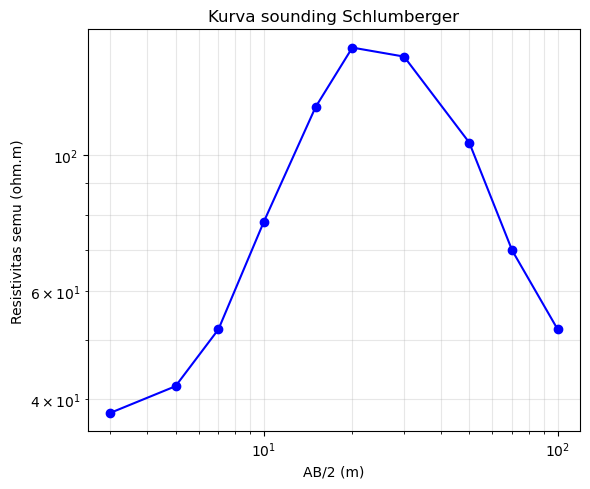

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("data", exist_ok=True)
os.makedirs("results/geolistrik", exist_ok=True)

# DATA CONTOH (dibuat sendiri untuk latihan), disimpan sebagai data/sounding.csv
contoh = pd.DataFrame({
    "titik": ["S%d" % (i + 1) for i in range(10)],
    "AB_2_m": [3, 5, 7, 10, 15, 20, 30, 50, 70, 100],
    "MN_2_m": [0.5, 0.5, 0.5, 1, 1, 1, 2.5, 2.5, 5, 5],
    "arus_mA": [50, 50, 50, 100, 100, 100, 150, 200, 200, 300],
    "beda_potensial_mV": [69.12, 27.01, 16.98, 50.16, 34.1, 23.93, 38.73, 13.4, 9.14, 4.98]})
contoh.to_csv("data/sounding.csv", index=False)

# [I] BACA DATA ASLI
data = pd.read_csv("data/sounding.csv")
konfigurasi = "Schlumberger"

# [K] PEMERIKSAAN DATA
kolom_wajib = ["titik", "AB_2_m", "MN_2_m", "arus_mA", "beda_potensial_mV"]
kurang = [k for k in kolom_wajib if k not in data.columns]
if len(kurang) > 0:
    raise SystemExit("Data tidak memadai, kolom belum ada: %s" % kurang)
if data[kolom_wajib].isna().any().any():
    raise SystemExit("Ada nilai kosong pada data.")
if (data["arus_mA"] <= 0).any() or (data["MN_2_m"] >= data["AB_2_m"]).any():
    raise SystemExit("Data tidak valid: arus <= 0 atau MN/2 >= AB/2.")
if (data["AB_2_m"] / data["MN_2_m"] < 5).any():
    print("PERINGATAN: ada titik dengan AB/MN < 5, syarat Schlumberger kurang terpenuhi.")

# [T] FAKTOR GEOMETRI DAN RESISTIVITAS SEMU
# K = pi * ((AB/2)^2 - (MN/2)^2) / (2 * (MN/2))        [meter]
# rho_a = K * dV / I   dengan dV dalam mV dan I dalam mA -> mV/mA = ohm, hasil ohm.m
K = np.pi * (data["AB_2_m"]**2 - data["MN_2_m"]**2) / (2 * data["MN_2_m"])
rho_a = K * data["beda_potensial_mV"] / data["arus_mA"]

hasil = pd.DataFrame({
    "titik": data["titik"],
    "AB_2_m": data["AB_2_m"],
    "K_m": K.round(2),
    "rho_a_ohm_m": rho_a.round(2)})
hasil.to_csv("results/geolistrik/resistivitas_semu.csv", index=False)

print("=== RESISTIVITAS SEMU (konfigurasi %s) ===" % konfigurasi)
print("Satuan: AB/2 dan MN/2 (m), arus (mA), beda potensial (mV), K (m), rho_a (ohm.m)")
print(hasil.to_string(index=False))
print("\nRumus yang dipakai:")
print("  K     = pi * ((AB/2)^2 - (MN/2)^2) / (2 * MN/2)   [m]")
print("  rho_a = K * dV / I                                 [ohm.m]")

# [Q] KRITERIA KUALITAS
print("\n=== KRITERIA KUALITAS ===")
print("Jumlah titik input = %d, output = %d -> %s" % (len(data), len(hasil), "SAMA" if len(data) == len(hasil) else "TIDAK SAMA"))
print("Semua K dan rho_a positif:", bool((K > 0).all() and (rho_a > 0).all()))

# [V] VERIFIKASI dengan contoh pada prompt
# AB/2 = 10 m, MN/2 = 1 m, arus 100 mA, beda potensial 50 mV -> K ~ 155,5 m dan rho_a ~ 77,8 ohm.m
K_uji = np.pi * (10**2 - 1**2) / (2 * 1)
rho_uji = K_uji * 50 / 100
print("\n=== VERIFIKASI ===")
print("K uji = %.1f m (harapan ~155.5) | rho_a uji = %.1f ohm.m (harapan ~77.8)" % (K_uji, rho_uji))
if abs(K_uji - 155.5) < 0.1 and abs(rho_uji - 77.8) < 0.1:
    print("Hasil: LULUS")
else:
    print("Hasil: GAGAL -> periksa rumus dan konversi satuan")

# [O] RENCANA.MD (narasi)
rencana = """# Rencana Perhitungan Resistivitas Semu (Schlumberger)

1. Baca data/sounding.csv tanpa mengubah isinya (AB/2 dan MN/2 dalam meter, arus dalam mA, beda potensial dalam mV).
2. Hitung faktor geometri K = pi * ((AB/2)^2 - (MN/2)^2) / (2 * MN/2) dalam meter.
3. Hitung resistivitas semu rho_a = K * dV / I. Karena mV dibagi mA sama dengan ohm, hasilnya dalam ohm.m.
4. Simpan tabel titik, AB/2, K, dan rho_a.
5. Periksa jumlah titik, semua nilai positif, dan cocokkan dengan contoh hitung (K sekitar 155,5 m dan rho_a sekitar 77,8 ohm.m).
6. Sajikan kurva rho_a terhadap AB/2 pada skala log-log. Tidak ada penafsiran lapisan bawah permukaan.
"""
with open("results/geolistrik/rencana.md", "w", encoding="utf-8") as f:
    f.write(rencana)

# GRAFIK
plt.figure(figsize=(6, 5))
plt.loglog(data["AB_2_m"], rho_a, "bo-")
plt.xlabel("AB/2 (m)")
plt.ylabel("Resistivitas semu (ohm.m)")
plt.title("Kurva sounding Schlumberger")
plt.grid(True, which="both", alpha=.3)
plt.tight_layout()
plt.savefig("results/geolistrik/kurva_sounding.png", dpi=150)
plt.show()


## Prompt 4 — Seismologi: Jarak Episenter dari Selisih Waktu Tiba Gelombang S dan P

### [R] Role
Bertindaklah sebagai asisten seismologi dasar. Fokus pada kecepatan gelombang, satuan waktu, dan selisih waktu tiba.

### [T] Task
Hitung jarak episenter dari selisih waktu tiba gelombang S dan P pada tiga stasiun, lalu rencanakan cara menentukan lokasi episenter dengan metode tiga lingkaran. Cukup rencana, jangan menggambar peta.

### [C] Context
Latihan mata kuliah untuk memahami hubungan waktu tiba dan jarak. Hasil hanya untuk belajar, bukan untuk pelaporan gempa.

### [I] Input
- `data/stasiun.csv`: kolom `stasiun`, `lat`, `lon`, `t_P_s` (detik), `t_S_s` (detik).
- Kecepatan Vp `{{6,0}}` km/s dan Vs `{{3,5}}` km/s.

### [K] Constraints
- Jangan mengubah data asli.
- Jangan menebak Vp dan Vs; tanyakan bila tidak jelas.
- Tulis asumsi model (bumi homogen) sebagai daftar terpisah.
- Software: Python dengan pandas dan numpy; tanpa jaringan.

### [O] Output (rencana teks)
- `results/seismo/jarak_episenter.csv`: `stasiun`, `ts_tp_s`, `jarak_km`.
- `results/seismo/rencana.md`: narasi rumus jarak dan langkah metode tiga lingkaran.

### [Q] Quality criteria
- Satuan detik dan kilometer ditulis eksplisit.
- Rumus jarak ditulis dan dipakai konsisten.
- Semua nilai jarak bernilai positif.

### [V] Optional verification
- Check: selisih S-P 10 detik dengan Vp 6,0 dan Vs 3,5 km/s. Expected: jarak sekitar 84 km. Jika gagal: periksa rumus.

---


In [4]:
import os
import numpy as np
import pandas as pd

os.makedirs("data", exist_ok=True)
os.makedirs("results/seismo", exist_ok=True)

# DATA CONTOH (dibuat sendiri untuk latihan), disimpan sebagai data/stasiun.csv
# Waktu tiba dalam detik terhadap jam referensi yang sama untuk semua stasiun.
contoh = pd.DataFrame({
    "stasiun": ['STA-A', 'STA-B', 'STA-C'],
    "lat": [-5.1, -2.6, -4.0],
    "lon": [119.5, 120.2, 121.8],
    "t_P_s": [145.07, 142.8, 155.36],
    "t_S_s": [162.99, 159.09, 180.62]})
contoh.to_csv("data/stasiun.csv", index=False)

# [I] BACA DATA ASLI
data = pd.read_csv("data/stasiun.csv")
Vp = 6.0      # km/s (dari prompt)
Vs = 3.5      # km/s (dari prompt)

# [K] PEMERIKSAAN DATA
kolom_wajib = ["stasiun", "lat", "lon", "t_P_s", "t_S_s"]
kurang = [k for k in kolom_wajib if k not in data.columns]
if len(kurang) > 0:
    raise SystemExit("Data tidak memadai, kolom belum ada: %s" % kurang)
if data[kolom_wajib].isna().any().any():
    raise SystemExit("Ada nilai kosong pada data.")
if len(data) != 3:
    raise SystemExit("Metode tiga lingkaran membutuhkan tepat 3 stasiun.")
if (data["t_S_s"] <= data["t_P_s"]).any():
    raise SystemExit("Ada stasiun dengan t_S <= t_P. Periksa data waktu tiba.")

print("=== ASUMSI MODEL ===")
print("1. Bumi homogen: Vp dan Vs konstan (Vp = %.1f km/s, Vs = %.1f km/s)." % (Vp, Vs))
print("2. Gelombang merambat lurus dari sumber ke stasiun.")
print("3. Jarak episenter dianggap sama dengan jarak sumber (kedalaman diabaikan).")
print("4. Permukaan bumi dianggap datar pada area kecil (lat/lon diubah ke km lokal).")
print("5. Jam semua stasiun sinkron.")

# [T] SELISIH S-P DAN JARAK
# jarak = (t_S - t_P) / (1/Vs - 1/Vp)    [km]
ts_tp = data["t_S_s"] - data["t_P_s"]
jarak = ts_tp / (1 / Vs - 1 / Vp)

hasil = pd.DataFrame({
    "stasiun": data["stasiun"],
    "ts_tp_s": ts_tp.round(2),
    "jarak_km": jarak.round(2)})
hasil.to_csv("results/seismo/jarak_episenter.csv", index=False)

print("\n=== JARAK EPISENTER (satuan: detik dan kilometer) ===")
print(hasil.to_string(index=False))
print("\nRumus: jarak = (t_S - t_P) / (1/Vs - 1/Vp)  [km]")

# METODE TIGA LINGKARAN (dihitung secara numerik, tanpa menggambar peta)
# lat/lon diubah ke koordinat lokal x (timur) dan y (utara) dalam km
lat0 = data["lat"].mean()
lon0 = data["lon"].mean()
x = (data["lon"] - lon0) * 111.32 * np.cos(np.radians(lat0))
y = (data["lat"] - lat0) * 110.57
d = jarak.values
x = x.values
y = y.values

# Kurangkan persamaan lingkaran stasiun 1 dari stasiun 2 dan 3 -> dua persamaan linear
A = np.array([[2 * (x[1] - x[0]), 2 * (y[1] - y[0])],
              [2 * (x[2] - x[0]), 2 * (y[2] - y[0])]])
b = np.array([d[0]**2 - d[1]**2 + x[1]**2 - x[0]**2 + y[1]**2 - y[0]**2,
              d[0]**2 - d[2]**2 + x[2]**2 - x[0]**2 + y[2]**2 - y[0]**2])
if abs(np.linalg.det(A)) < 1e-6:
    raise SystemExit("Tiga stasiun hampir segaris, lokasi tidak dapat ditentukan.")
xe, ye = np.linalg.solve(A, b)
lat_e = lat0 + ye / 110.57
lon_e = lon0 + xe / (111.32 * np.cos(np.radians(lat0)))

print("\n=== LOKASI EPISENTER (metode tiga lingkaran) ===")
print("Perkiraan: lat = %.3f, lon = %.3f" % (lat_e, lon_e))
jarak_cek = np.sqrt((x - xe)**2 + (y - ye)**2)
for i in range(3):
    print("  %s: jarak hitung %.1f km, jarak ke titik hasil %.1f km" % (data["stasiun"].iloc[i], d[i], jarak_cek[i]))

# [Q] KRITERIA KUALITAS
print("\n=== KRITERIA KUALITAS ===")
print("Semua jarak positif:", bool((jarak > 0).all()))
print("Satuan: waktu dalam detik (s), jarak dalam kilometer (km).")

# [V] VERIFIKASI: selisih S-P 10 detik, Vp 6,0 dan Vs 3,5 km/s -> sekitar 84 km
jarak_uji = 10 / (1 / 3.5 - 1 / 6.0)
print("\n=== VERIFIKASI ===")
print("Jarak uji = %.1f km (harapan sekitar 84 km)" % jarak_uji)
if abs(jarak_uji - 84) < 0.5:
    print("Hasil: LULUS")
else:
    print("Hasil: GAGAL -> periksa rumus")

# [O] RENCANA.MD (narasi)
rencana = """# Rencana Penentuan Jarak dan Episenter

1. Baca data/stasiun.csv tanpa mengubah isinya.
2. Hitung selisih waktu tiba S dan P tiap stasiun (t_S - t_P) dalam detik.
3. Hitung jarak: d = (t_S - t_P) / (1/Vs - 1/Vp), dengan Vp = 6.0 km/s dan Vs = 3.5 km/s.
4. Metode tiga lingkaran: gambarkan lingkaran berjari-jari d di sekitar tiap stasiun. Titik potong ketiganya adalah episenter.
5. Secara hitungan, selisihkan persamaan lingkaran stasiun 1 dengan stasiun 2 dan 3 sehingga diperoleh dua persamaan linear, lalu selesaikan untuk koordinat episenter.
6. Catat asumsi model (bumi homogen) dan lakukan verifikasi dengan contoh S-P = 10 detik (sekitar 84 km).
"""
with open("results/seismo/rencana.md", "w", encoding="utf-8") as f:
    f.write(rencana)


=== ASUMSI MODEL ===
1. Bumi homogen: Vp dan Vs konstan (Vp = 6.0 km/s, Vs = 3.5 km/s).
2. Gelombang merambat lurus dari sumber ke stasiun.
3. Jarak episenter dianggap sama dengan jarak sumber (kedalaman diabaikan).
4. Permukaan bumi dianggap datar pada area kecil (lat/lon diubah ke km lokal).
5. Jam semua stasiun sinkron.

=== JARAK EPISENTER (satuan: detik dan kilometer) ===
stasiun  ts_tp_s  jarak_km
  STA-A    17.92    150.53
  STA-B    16.29    136.84
  STA-C    25.26    212.18

Rumus: jarak = (t_S - t_P) / (1/Vs - 1/Vp)  [km]

=== LOKASI EPISENTER (metode tiga lingkaran) ===
Perkiraan: lat = -3.800, lon = 119.900
  STA-A: jarak hitung 150.5 km, jarak ke titik hasil 150.5 km
  STA-B: jarak hitung 136.8 km, jarak ke titik hasil 136.8 km
  STA-C: jarak hitung 212.2 km, jarak ke titik hasil 212.1 km

=== KRITERIA KUALITAS ===
Semua jarak positif: True
Satuan: waktu dalam detik (s), jarak dalam kilometer (km).

=== VERIFIKASI ===
Jarak uji = 84.0 km (harapan sekitar 84 km)
Hasil: LULU

## Prompt 5 — Klimatologi: Rata-Rata dan Anomali Suhu Udara Bulanan

### [R] Role
Bertindaklah sebagai analis klimatologi dasar. Fokus pada satuan, urutan bulan, dan periode rujukan.

### [T] Task
Hitung rata-rata suhu udara untuk tiap bulan dari data beberapa tahun sebagai nilai klimatologi, lalu hitung anomali tiap bulan terhadap nilai itu dan rencanakan grafik tren anomali. Cukup rencana grafik dalam narasi.

### [C] Context
Latihan mata kuliah klimatologi untuk memahami konsep anomali. Hasil hanya untuk belajar, bukan untuk pernyataan tentang perubahan iklim.

### [I] Input
- `data/suhu_bulanan.csv`: kolom `tahun`, `bulan`, `suhu_c` (derajat Celsius). Stasiun `{{nama stasiun}}`.
- Periode rujukan klimatologi: `{{2015 sampai 2024}}`.

### [K] Constraints
- Jangan mengubah data asli.
- Jangan mengisi bulan yang kosong; laporkan saja.
- Jangan menebak satuan suhu; tanyakan bila tidak jelas.
- Software: Python dengan pandas; tanpa jaringan.

### [O] Output (rencana teks)
- `results/suhu/klimatologi_bulanan.csv`: `bulan`, `rata_rata_c`.
- `results/suhu/anomali.csv`: `tahun`, `bulan`, `anomali_c`.
- `results/suhu/rencana.md`: narasi cara menghitung anomali dan rencana grafik tren.

### [Q] Quality criteria
- Tabel klimatologi berisi 12 baris, satu per bulan.
- Satuan derajat Celsius ditulis eksplisit.
- Bulan yang kosong dilaporkan dan tidak diisi.

### [V] Optional verification
- Check: rata-rata anomali tiap bulan pada periode rujukan. Expected: mendekati 0. Jika gagal: periksa perhitungan rata-rata.

---


=== BULAN KOSONG (dilaporkan, tidak diisi) ===
Stasiun: Stasiun contoh (Makassar) | Periode rujukan: 2015-2024
Jumlah bulan kosong: 4
  tahun 2016 bulan 3
  tahun 2016 bulan 4
  tahun 2019 bulan 5
  tahun 2023 bulan 2

=== KLIMATOLOGI BULANAN (derajat Celsius) ===
 bulan  rata_rata_c
     1       27.709
     2       27.906
     3       28.396
     4       28.414
     5       28.379
     6       28.021
     7       27.547
     8       27.024
     9       26.864
    10       26.756
    11       26.877
    12       27.323

=== 10 BARIS PERTAMA ANOMALI (derajat Celsius) ===
 tahun  bulan  anomali_c
  2015      1      0.211
  2015      2     -0.126
  2015      3     -0.196
  2015      4     -0.014
  2015      5     -0.379
  2015      6     -0.121
  2015      7     -0.047
  2015      8     -0.364
  2015      9      0.196
  2015     10      0.094
Rumus: anomali = suhu_bulan - rata_rata_klimatologi_bulan

=== KRITERIA KUALITAS ===
Tabel klimatologi berisi 12 baris -> OK (12 baris)
Bulan kosong

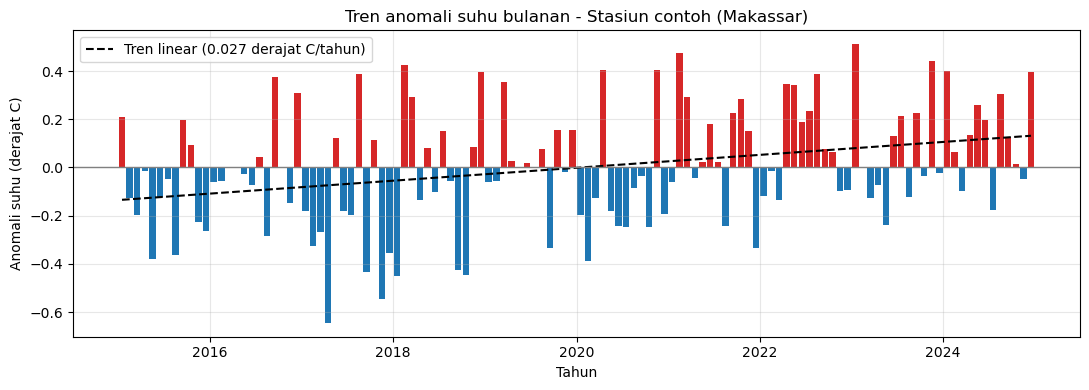


Catatan: tren ini hanya latihan, bukan pernyataan tentang perubahan iklim.


In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("data", exist_ok=True)
os.makedirs("results/suhu", exist_ok=True)

# DATA CONTOH (dibuat sendiri untuk latihan), disimpan sebagai data/suhu_bulanan.csv
np.random.seed(7)
tahun_c = np.repeat(np.arange(2015, 2025), 12)
bulan_c = np.tile(np.arange(1, 13), 10)
musim = 0.8 * np.cos(2 * np.pi * (bulan_c - 4) / 12)           # pola musiman
tren = 0.02 * (tahun_c - 2015)                                  # kenaikan kecil
suhu_c = 27.5 + musim + tren + np.random.normal(0, 0.25, len(tahun_c))
contoh = pd.DataFrame({"tahun": tahun_c, "bulan": bulan_c, "suhu_c": suhu_c.round(2)})
contoh = contoh.drop(index=[14, 15, 52, 97]).reset_index(drop=True)   # 4 bulan sengaja kosong
contoh.to_csv("data/suhu_bulanan.csv", index=False)

# [I] BACA DATA ASLI
data = pd.read_csv("data/suhu_bulanan.csv")
nama_stasiun = "Stasiun contoh (Makassar)"
tahun_awal = 2015
tahun_akhir = 2024

# [K] PEMERIKSAAN DATA
kolom_wajib = ["tahun", "bulan", "suhu_c"]
kurang = [k for k in kolom_wajib if k not in data.columns]
if len(kurang) > 0:
    raise SystemExit("Data tidak memadai, kolom belum ada: %s" % kurang)
if data["suhu_c"].min() < 10 or data["suhu_c"].max() > 45:
    print("PERINGATAN: suhu di luar 10-45, pastikan satuannya derajat Celsius.")
if data.duplicated(subset=["tahun", "bulan"]).any():
    raise SystemExit("Ada data ganda untuk tahun dan bulan yang sama.")

# Bulan yang kosong hanya DILAPORKAN, tidak diisi
semua = pd.MultiIndex.from_product([range(tahun_awal, tahun_akhir + 1), range(1, 13)], names=["tahun", "bulan"])
ada = pd.MultiIndex.from_frame(data[["tahun", "bulan"]])
kosong = semua.difference(ada)
print("=== BULAN KOSONG (dilaporkan, tidak diisi) ===")
print("Stasiun: %s | Periode rujukan: %d-%d" % (nama_stasiun, tahun_awal, tahun_akhir))
print("Jumlah bulan kosong: %d" % len(kosong))
for t, bl in kosong:
    print("  tahun %d bulan %d" % (t, bl))

# [T] KLIMATOLOGI BULANAN (rata-rata tiap bulan pada periode rujukan)
rujukan = data[(data["tahun"] >= tahun_awal) & (data["tahun"] <= tahun_akhir)]
klimatologi = rujukan.groupby("bulan")["suhu_c"].mean().round(3).reset_index()
klimatologi.columns = ["bulan", "rata_rata_c"]
klimatologi.to_csv("results/suhu/klimatologi_bulanan.csv", index=False)
print("\n=== KLIMATOLOGI BULANAN (derajat Celsius) ===")
print(klimatologi.to_string(index=False))

# ANOMALI = suhu bulan itu - rata-rata klimatologi bulan yang sama
data = data.merge(klimatologi, on="bulan", how="left")
data["anomali_c"] = (data["suhu_c"] - data["rata_rata_c"]).round(3)
anomali = data[["tahun", "bulan", "anomali_c"]].sort_values(["tahun", "bulan"]).reset_index(drop=True)
anomali.to_csv("results/suhu/anomali.csv", index=False)
print("\n=== 10 BARIS PERTAMA ANOMALI (derajat Celsius) ===")
print(anomali.head(10).to_string(index=False))
print("Rumus: anomali = suhu_bulan - rata_rata_klimatologi_bulan")

# [Q] KRITERIA KUALITAS
print("\n=== KRITERIA KUALITAS ===")
print("Tabel klimatologi berisi %d baris -> %s" % (len(klimatologi), "OK (12 baris)" if len(klimatologi) == 12 else "TIDAK 12 BARIS"))
print("Bulan kosong dilaporkan: %d bulan, tidak diisi." % len(kosong))

# [V] VERIFIKASI: rata-rata anomali tiap bulan pada periode rujukan harus mendekati 0
cek = data[(data["tahun"] >= tahun_awal) & (data["tahun"] <= tahun_akhir)].groupby("bulan")["anomali_c"].mean()
print("\n=== VERIFIKASI ===")
print("Rata-rata anomali per bulan (harapan mendekati 0):")
print(cek.round(4).to_string())
if (cek.abs() < 0.001).all():
    print("Hasil: LULUS")
else:
    print("Hasil: GAGAL -> periksa perhitungan rata-rata")

# [O] RENCANA.MD (narasi)
rencana = """# Rencana Analisis Anomali Suhu Bulanan

1. Baca data/suhu_bulanan.csv tanpa mengubah isinya (suhu dalam derajat Celsius).
2. Laporkan bulan yang kosong, jangan diisi.
3. Hitung rata-rata suhu tiap bulan (Januari sampai Desember) pada periode rujukan 2015-2024 sebagai klimatologi.
4. Hitung anomali tiap bulan = suhu bulan itu dikurangi klimatologi bulan yang sama.
5. Grafik tren: sumbu x waktu (tahun dan bulan), sumbu y anomali (derajat Celsius). Batang merah untuk anomali positif, biru untuk negatif, ditambah garis tren linear.
6. Verifikasi: rata-rata anomali tiap bulan pada periode rujukan harus mendekati nol.
"""
with open("results/suhu/rencana.md", "w", encoding="utf-8") as f:
    f.write(rencana)

# GRAFIK TREN ANOMALI
waktu = anomali["tahun"] + (anomali["bulan"] - 0.5) / 12
warna = np.where(anomali["anomali_c"] >= 0, "tab:red", "tab:blue")
koef = np.polyfit(waktu, anomali["anomali_c"], 1)
plt.figure(figsize=(11, 4))
plt.bar(waktu, anomali["anomali_c"], width=0.07, color=warna)
plt.plot(waktu, koef[0] * waktu + koef[1], "k--", label="Tren linear (%.3f derajat C/tahun)" % koef[0])
plt.axhline(0, color="gray", lw=1)
plt.xlabel("Tahun"); plt.ylabel("Anomali suhu (derajat C)")
plt.title("Tren anomali suhu bulanan - %s" % nama_stasiun)
plt.legend(); plt.grid(True, alpha=.3)
plt.tight_layout()
plt.savefig("results/suhu/grafik_anomali.png", dpi=150)
plt.show()
print("\nCatatan: tren ini hanya latihan, bukan pernyataan tentang perubahan iklim.")
